# Notebook 05 — Model Evaluation & Banking Validation
## Objetivo
Evaluar el pipeline XGBoost seleccionado en el Notebook 04 sobre el holdout del Notebook 03. Fuente: [UCI Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), Taiwán, 2005; horizonte de un mes. No es una PD regulatoria anual ni un modelo validado para México.

**Protocolo:** no ajustar hiperparámetros, calibrador ni umbral con test. El umbral 0.5 es una referencia diagnóstica. Los deciles son descriptivos, no políticas de crédito. La exploración previa de todo el dataset limita la independencia estricta del holdout; para una validación confirmatoria se necesita una nueva muestra externa o temporal.

## 1. Configuración
Usa el mismo kernel que en Notebook 04. Si faltan paquetes, ejecuta `%pip install pandas numpy matplotlib scipy scikit-learn xgboost joblib` y reinicia el kernel.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from scipy.stats import ks_2samp
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
    precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, brier_score_loss, log_loss)
from sklearn.calibration import calibration_curve
from IPython.display import display
TARGET = "DEFAULT"
THRESHOLD = 0.5
root = Path.cwd()
if root.name.lower() == "notebooks":
    root = root.parent
processed = root / "data" / "processed"
models = root / "models"
figures = root / "reports" / "figures"
figures.mkdir(parents=True, exist_ok=True)
print(sys.executable, sklearn.__version__, root)

C:\Users\pirom\anaconda3\python.exe 1.8.0 C:\Users\pirom\OneDrive\Documentos\Proyectos\credit_risk_scoring


## 2. Carga y validación
Se reutiliza el pipeline completo, incluida la imputación aprendida en train. Carga únicamente archivos joblib propios y confiables. Se exige que el candidato guardado sea XGBoost y que el esquema coincida con el manifiesto.

In [2]:
paths = [processed / "feature_manifest.json", models / "model_metadata.json",
         models / "best_model.joblib", processed / "credit_risk_train_features.csv",
         processed / "credit_risk_test_features.csv"]
for path in paths:
    if not path.exists():
        raise FileNotFoundError(f"Falta {path}. Ejecuta Notebooks 03 y 04 desde la raíz correcta.")
manifest = json.loads(paths[0].read_text(encoding="utf-8"))
meta = json.loads(paths[1].read_text(encoding="utf-8"))
assert meta["model"] == "XGBoost", f"El candidato guardado es {meta['model']}, no XGBoost. Revisa Notebook 04."
assert meta["target"] == manifest["target"] == TARGET
assert meta["test_used"] is False
features = manifest["features"]
assert features == meta["features"] and len(features) == len(set(features))
assert set(features).isdisjoint([TARGET, "row_id"] + manifest["audit_only"])
if meta.get("sklearn_version") != sklearn.__version__:
    print("Advertencia: versión de sklearn diferente de la utilizada al entrenar.")
train, test = pd.read_csv(paths[3]), pd.read_csv(paths[4])
for frame in [train, test]:
    assert set(frame.columns) == set(features + [TARGET, "row_id"])
    assert frame.row_id.is_unique and frame.row_id.notna().all()
    assert frame[TARGET].isin([0, 1]).all() and frame[TARGET].nunique() == 2
assert set(train.row_id).isdisjoint(test.row_id)
model = joblib.load(paths[2])
assert type(model.named_steps["model"]).__name__ == "XGBClassifier"
assert list(model.feature_names_in_) == features
assert list(model.classes_) == [0, 1]
def inputs(frame):
    return frame[features].apply(pd.to_numeric, errors="raise").replace([np.inf,-np.inf],np.nan), frame[TARGET].astype(int)
X_train, y_train = inputs(train)
X_test, y_test = inputs(test)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Prevalencia test:", y_test.mean())

Train: (24000, 34) Test: (6000, 34)
Prevalencia test: 0.22116666666666668


## 3. Predicciones y métricas
PD bruta = predict_proba de la clase 1. Gini = 2 AUC − 1. KS = máxima distancia absoluta entre las distribuciones empíricas de scores de las dos clases. AP resume precision-recall; no es el área trapezoidal. Brier y log loss: menor es mejor.

In [3]:
p_train = model.predict_proba(X_train)[:,1]
p_test = model.predict_proba(X_test)[:,1]
for p in [p_train,p_test]:
    assert np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
def metrics(y,p):
    pred = (p >= THRESHOLD).astype(int)
    auc = roc_auc_score(y,p)
    return dict(roc_auc=auc, ap=average_precision_score(y,p), gini=2*auc-1,
                ks=ks_2samp(p[np.asarray(y)==0],p[np.asarray(y)==1]).statistic,
                accuracy=accuracy_score(y,pred), precision=precision_score(y,pred,zero_division=0),
                recall=recall_score(y,pred), f1=f1_score(y,pred,zero_division=0),
                brier=brier_score_loss(y,p), log_loss=log_loss(y,p),
                prevalence=y.mean(), mean_pd=p.mean())
summary = pd.DataFrame([metrics(y_train,p_train), metrics(y_test,p_test)],index=["train_in_sample","test"])
display(summary.T.round(4))
print("AP CV:", meta["cv_ap"], "AP test:", summary.loc["test","ap"])
print("AUC CV:", meta["cv_roc_auc"], "AUC test:", summary.loc["test","roc_auc"])
print("Brier referencia (prevalencia train):", brier_score_loss(y_test,np.full(len(y_test),y_train.mean())))

,train_in_sample,test
roc_auc,0.8061,0.7806
ap,0.5923,0.5614
gini,0.6121,0.5612
ks,0.4600,0.4317
accuracy,0.8250,0.8202
precision,0.6914,0.6689
recall,0.3773,0.3700
f1,0.4882,0.4765
brier,0.1293,0.1344
log_loss,0.4125,0.4285


AP CV: 0.5612786566814469 AP test: 0.561428424280558
AUC CV: 0.7867971480695545 AUC test: 0.7806145906086224
Brier referencia (prevalencia train): 0.17225197395833333


Train in-sample es optimista; compara principalmente CV y test. Una caída de rendimiento puede sugerir sobreajuste, pero no lo demuestra por sí sola.

In [4]:
def finish(name):
    plt.tight_layout()
    plt.savefig(figures / name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
ConfusionMatrixDisplay.from_predictions(y_test, p_test>=THRESHOLD, display_labels=["No default","Default"], cmap="Blues")
plt.title("Test — matriz de confusión (umbral 0.5)")
finish("test_confusion_matrix.png")
tn,fp,fn,tp = confusion_matrix(y_test,p_test>=THRESHOLD,labels=[0,1]).ravel()
print(dict(TN=int(tn),FP=int(fp),FN=int(fn),TP=int(tp)))

<Figure size 640x480 with 2 Axes>

{'TN': 4430, 'FP': 243, 'FN': 836, 'TP': 491}


## 4. Curvas ROC y Precision-Recall
ROC: sensibilidad frente a falsos positivos. PR: precisión frente a recall; la referencia es la prevalencia test.

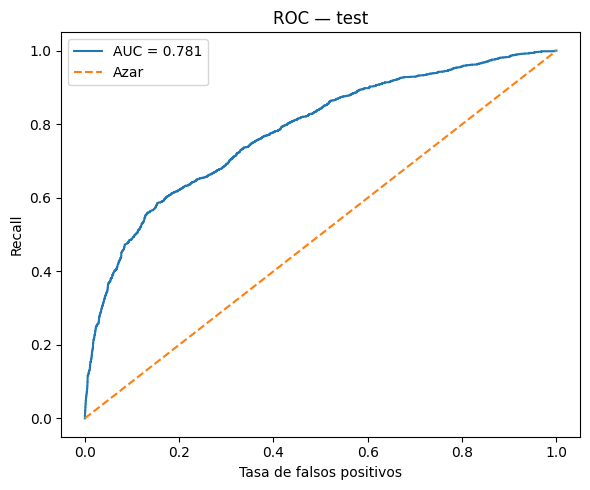

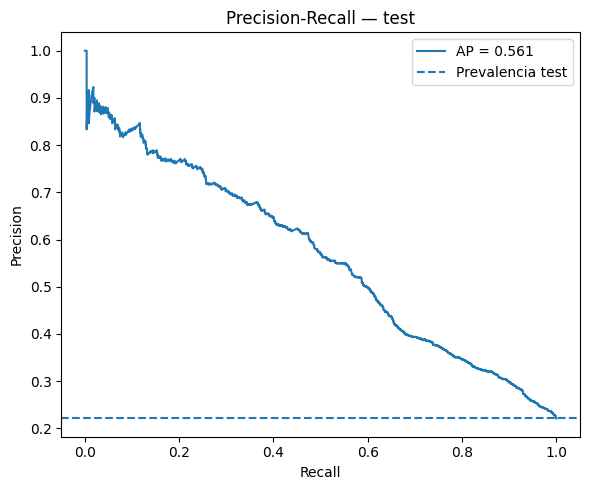

In [9]:
fpr,tpr,thresholds = roc_curve(y_test,p_test,drop_intermediate=False)
plt.figure(figsize=(6,5)); plt.plot(fpr,tpr,label=f'AUC = {summary.loc["test","roc_auc"]:.3f}')
plt.plot([0,1],[0,1],"--",label="Azar"); plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Recall"); plt.title("ROC — test"); plt.legend(); finish("test_roc.png")
precision,recall,_ = precision_recall_curve(y_test,p_test)
plt.figure(figsize=(6,5))
plt.plot(recall,precision,label=f'AP = {summary.loc["test","ap"]:.3f}')
plt.axhline(y_test.mean(),ls="--",label="Prevalencia test")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall — test")
plt.legend()
finish("test_pr.png")

## 5. KS bancario
Se grafican las CDF empíricas por clase; el máximo de su diferencia absoluta coincide con el KS de dos muestras. No se utiliza el punto de máximo KS para elegir un umbral operativo en test.

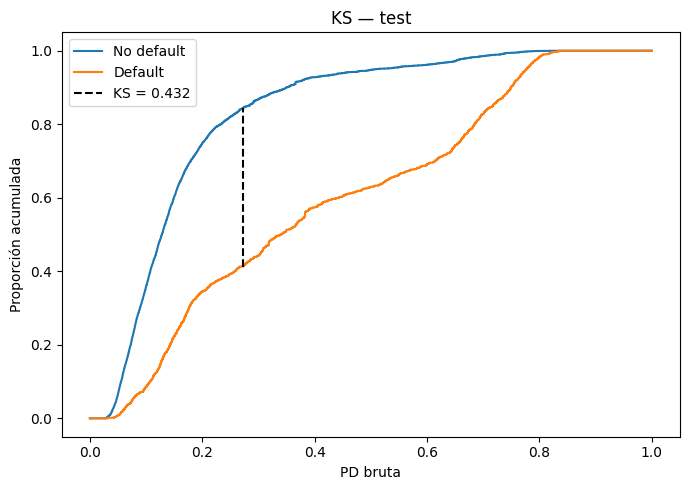

In [10]:
grid = np.unique(np.r_[0,p_test,1])
cdf0 = np.searchsorted(np.sort(p_test[y_test.to_numpy()==0]),grid,side="right") / (y_test==0).sum()
cdf1 = np.searchsorted(np.sort(p_test[y_test.to_numpy()==1]),grid,side="right") / (y_test==1).sum()
k = np.argmax(np.abs(cdf0-cdf1)); ks = abs(cdf0[k]-cdf1[k])
np.testing.assert_allclose(ks,summary.loc["test","ks"])
plt.figure(figsize=(7,5)); plt.step(grid,cdf0,where="post",label="No default"); plt.step(grid,cdf1,where="post",label="Default")
plt.vlines(grid[k],min(cdf0[k],cdf1[k]),max(cdf0[k],cdf1[k]),color="black",ls="--",label=f"KS = {ks:.3f}")
plt.xlabel("PD bruta")
plt.ylabel("Proporción acumulada")
plt.title("KS — test")
plt.legend()
finish("test_ks.png")

## 6. Diagnóstico de calibración
Compara PD media con frecuencia observada por grupos de tamaño similar. Una curva cercana a la diagonal sugiere buena calibración; no garantiza calibración individual. Se evalúa, no se ajusta el calibrador en test. Para calibrar en la siguiente fase, usar predicciones fuera de fold de train o una partición de calibración independiente.

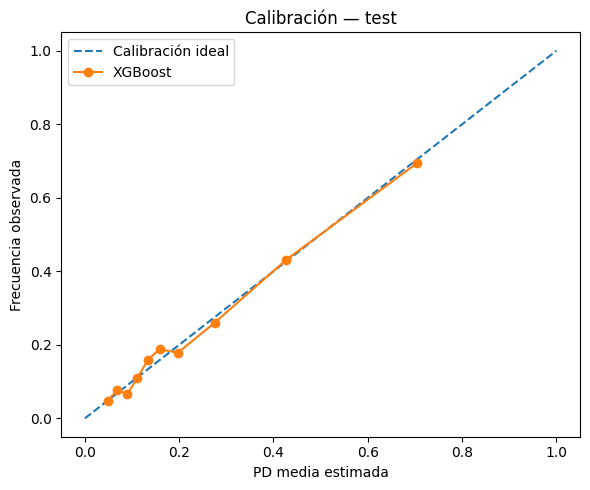

PD media: 0.22138609 Default observado: 0.22116666666666668


In [11]:
observed,predicted = calibration_curve(y_test,p_test,n_bins=10,strategy="quantile")
plt.figure(figsize=(6,5)); plt.plot([0,1],[0,1],"--",label="Calibración ideal"); plt.plot(predicted,observed,"o-",label="XGBoost")
plt.xlabel("PD media estimada"); plt.ylabel("Frecuencia observada"); plt.title("Calibración — test"); plt.legend(); finish("test_calibration.png")
print("PD media:",p_test.mean(),"Default observado:",y_test.mean())

## 7. Deciles de riesgo, Lift y Gain
Ordenamos por PD descendente; decil 1 contiene los scores más altos. Los empates se resuelven por row_id de forma reproducible, lo que puede dividir scores idénticos. No son cortes operativos. Lift = tasa del grupo / tasa global; Gain acumulado = incumplimientos capturados / total de incumplimientos.

In [12]:
scores = pd.DataFrame({"row_id":test.row_id,"DEFAULT":y_test,"pd_raw":p_test,"prediction":(p_test>=THRESHOLD).astype(int)})
scores = scores.sort_values(["pd_raw","row_id"],ascending=[False,True]).reset_index(drop=True)
assert len(scores)>=10
scores["decile"] = np.arange(len(scores))*10//len(scores)+1
deciles = scores.groupby("decile").agg(clientes=(TARGET,"size"),defaults=(TARGET,"sum"),pd_media=("pd_raw","mean"),pd_min=("pd_raw","min"),pd_max=("pd_raw","max"))
deciles["default_rate"] = deciles.defaults/deciles.clientes
deciles["lift"] = deciles.default_rate/y_test.mean()
deciles["population_cum"] = deciles.clientes.cumsum()/len(scores)
deciles["gain_cum"] = deciles.defaults.cumsum()/y_test.sum()
deciles["lift_cum"] = deciles.gain_cum/deciles.population_cum
assert deciles.clientes.sum()==len(test) and deciles.defaults.sum()==y_test.sum()
np.testing.assert_allclose(deciles.gain_cum.iloc[-1],1)
display(deciles.round(4))
print(f"Primer decil: lift={deciles.lift.iloc[0]:.2f}x; captura={deciles.gain_cum.iloc[0]:.1%}")

,clientes,defaults,pd_media,pd_min,pd_max,default_rate,lift,population_cum,gain_cum,lift_cum
decile,,,,,,,,,,
1,600,416,0.7035,0.5920,0.8337,0.6933,3.1349,0.1,0.3135,3.1349
2,600,259,0.4274,0.3291,0.5919,0.4317,1.9518,0.2,0.5087,2.5433
3,600,156,0.2751,0.2250,0.3289,0.2600,1.1756,0.3,0.6262,2.0874
4,600,107,0.1970,0.1743,0.2249,0.1783,0.8063,0.4,0.7069,1.7671
5,600,113,0.1590,0.1457,0.1742,0.1883,0.8515,0.5,0.7920,1.5840
6,600,96,0.1339,0.1224,0.1456,0.1600,0.7234,0.6,0.8644,1.4406
7,600,66,0.1113,0.1004,0.1223,0.1100,0.4974,0.7,0.9141,1.3058
8,600,39,0.0894,0.0789,0.1004,0.0650,0.2939,0.8,0.9435,1.1794
9,600,47,0.0692,0.0590,0.0789,0.0783,0.3542,0.9,0.9789,1.0877


Primer decil: lift=3.13x; captura=31.3%


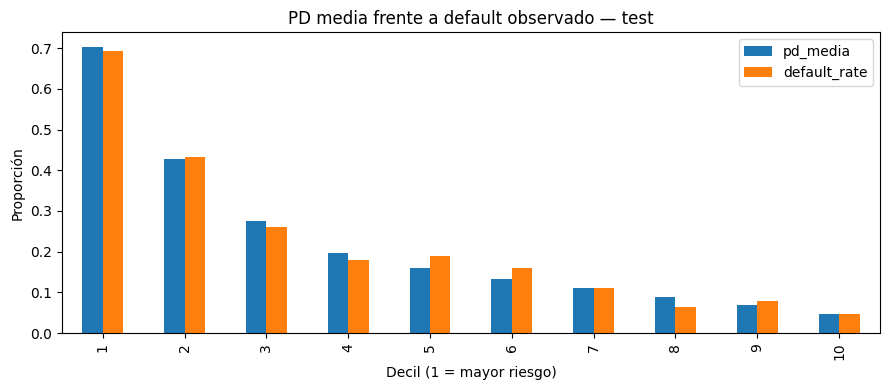

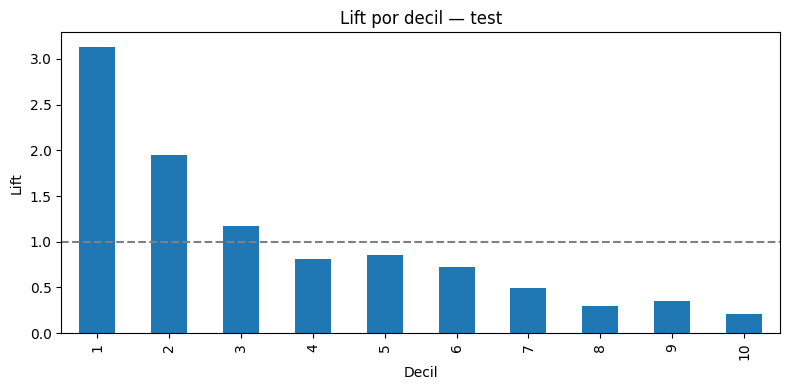

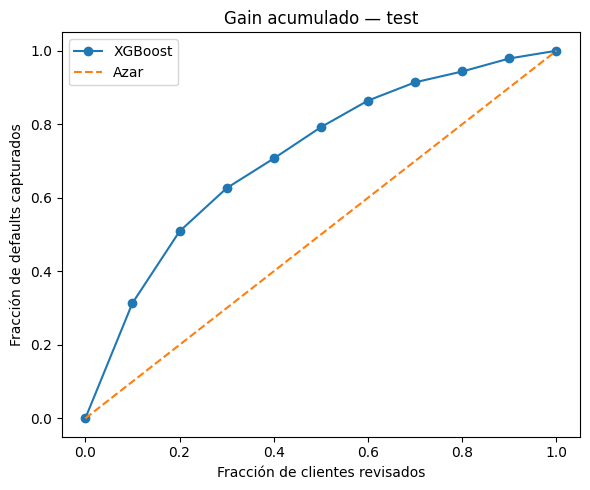

In [13]:
ax=deciles[["pd_media","default_rate"]].plot.bar(figsize=(9,4)); ax.set(xlabel="Decil (1 = mayor riesgo)",ylabel="Proporción",title="PD media frente a default observado — test"); finish("test_decile_calibration.png")
ax=deciles.lift.plot.bar(figsize=(8,4)); ax.axhline(1,ls="--",color="gray"); ax.set(xlabel="Decil",ylabel="Lift",title="Lift por decil — test"); finish("test_lift.png")
plt.figure(figsize=(6,5)); plt.plot(np.r_[0,deciles.population_cum],np.r_[0,deciles.gain_cum],"o-",label="XGBoost"); plt.plot([0,1],[0,1],"--",label="Azar"); plt.xlabel("Fracción de clientes revisados"); plt.ylabel("Fracción de defaults capturados"); plt.title("Gain acumulado — test"); plt.legend(); finish("test_gain.png")

## 8. Exportación y conclusiones
Los scores conservan row_id para auditoría; no incluyen datos demográficos. No publicar registros individuales en GitHub. Las métricas representan este holdout histórico, no una certificación bancaria.

In [14]:
summary.to_csv(processed/"model_test_metrics.csv",index_label="split")
deciles.to_csv(processed/"risk_deciles.csv")
scores.to_csv(processed/"test_predictions.csv",index=False)
report = {"model":meta["model"],"threshold":THRESHOLD,"calibrated":meta.get("calibrated",False),
          "n_test":len(test),"cv_ap":meta["cv_ap"],"cv_roc_auc":meta["cv_roc_auc"],
          "test":{k:float(v) for k,v in summary.loc["test"].items()},
          "first_decile_lift":float(deciles.lift.iloc[0]),"first_decile_gain":float(deciles.gain_cum.iloc[0])}
(models/"evaluation_metadata.json").write_text(json.dumps(report,indent=2),encoding="utf-8")
print(f"Test: AUC {report['test']['roc_auc']:.3f}; AP {report['test']['ap']:.3f}; KS {report['test']['ks']:.3f}; Brier {report['test']['brier']:.3f}")
print("Archivos guardados en",processed,figures)

Test: AUC 0.781; AP 0.561; KS 0.432; Brier 0.134
Archivos guardados en C:\Users\pirom\OneDrive\Documentos\Proyectos\credit_risk_scoring\data\processed C:\Users\pirom\OneDrive\Documentos\Proyectos\credit_risk_scoring\reports\figures


## 9. Siguiente fase
Optimizar hiperparámetros, calibrar PD y seleccionar un umbral de costos usando exclusivamente desarrollo. Si este diagnóstico inspira cambios, reservar otra muestra independiente para confirmar el modelo final. Documentar LGD/EAD como supuestos, no como observaciones de UCI. Evaluar estabilidad temporal y equidad antes de cualquier uso real.